In [1]:
###################################
# Cell 1: Import
###################################
import os
import json
import random
import copy
from pathlib import Path
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import (Dataset, DataLoader, random_split, Subset,)
from PIL import Image
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm


e:\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Đang sử dụng CPU")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Device: cuda


In [3]:
!nvidia-smi

Fri Oct 16 12:19:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.47                 KMD Version: 610.47        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   43C    P0            590W /   80W |       0MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
###################################
# Cell 2: Config
###################################

EPOCHS = 40
BATCH_SIZE = 64
LR = 1e-4
NUM_CLASSES = 10
SEED = 42
IMAGE_SIZE = 28

# Trong quá trình train, thì cần tải 1 loader (1 load theo batch size) thì nó có thể chuẩn bị data tiến trình song song lúc batch thứ i đang train
NUM_WORKERS = 0


# Path
CHECKPOINT_DIR = Path("./06_checkpoints")
RUN_DIR = CHECKPOINT_DIR / "run"
SAVE_BEST_DIR = CHECKPOINT_DIR / "best"

DATA_DIR = Path("./../../.data/mnist/images")
TRAIN_DATA_DIR = DATA_DIR / "train"
VAL_DATA_DIR = DATA_DIR / "val"
TEST_DATA_DIR = DATA_DIR / "test"


RUN_DIR.mkdir(parents=True, exist_ok=True)
SAVE_BEST_DIR.mkdir(parents=True, exist_ok=True)

print(CHECKPOINT_DIR)
print(DATA_DIR)

06_checkpoints
..\..\.data\mnist\images


Kích thước (W, H): (28, 28)
Chế độ màu: L


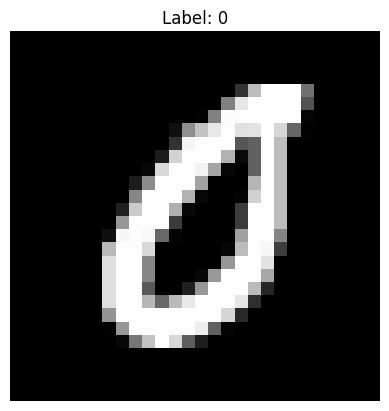

In [5]:
###################################
# Cell 3: Data processing
###################################

# 1. Đường dẫn tới 1 ảnh mẫu (dựa theo biến TRAIN_DATA_DIR bạn đã tạo ở Cell 2)
img_path = TRAIN_DATA_DIR / "0" / "00006.png"

# 2. Đọc ảnh
# Dùng .convert("L") để đảm bảo ảnh ở dạng Grayscale (ảnh xám 1 kênh), rất cần thiết cho MNIST
img = Image.open(img_path).convert("L")

# 3. Xem thông tin cơ bản
print("Kích thước (W, H):", img.size)     # MNIST thường là (28, 28)
print("Chế độ màu:", img.mode)           # 'L' (Grayscale)
# 4. Hiển thị ảnh bằng matplotlib
plt.imshow(img, cmap="gray")
plt.title("Label: 0")
plt.axis("off")
plt.show()


In [6]:
###################################
# Cell 4: Image Dataset
###################################

class ImageDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None):
        self.csv_path = Path(csv_path)
        self.image_dir = Path(image_dir)
        self.transform = transform

        # Đọc CSV một lần khi khởi tạo Dataset
        self.data = pd.read_csv(self.csv_path)

        # Chuẩn hóa nhãn thành số nguyên
        self.data["label"] = self.data["label"].astype(int)

        print(f"Loaded CSV: {self.csv_path}")
        print(f"Number of images: {len(self.data)}")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Lấy thông tin của một mẫu
        row = self.data.iloc[idx]

        filename = str(row["filename"])
        label = int(row["label"])
        image_path = self.image_dir / str(label) / filename

        # Mở ảnh và chuyển thành grayscale
        with Image.open(image_path) as img:
            image = img.convert("L")

        # Chuyển đổi ảnh nếu có transform
        if self.transform is not None:
            image = self.transform(image)

        # Trả về tensor ảnh và nhãn
        return image, label


In [7]:
###################################
# Cell 5: 
###################################

transform = transforms.ToTensor()


train_dataset = ImageDataset(
    csv_path=TRAIN_DATA_DIR / "labels.csv",
    image_dir=TRAIN_DATA_DIR,
    transform=transform
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)


val_dataset = ImageDataset(
    csv_path=VAL_DATA_DIR / "labels.csv",
    image_dir=VAL_DATA_DIR,
    transform=transform
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_dataset = ImageDataset(
    csv_path=TEST_DATA_DIR / "labels.csv",
    image_dir=TEST_DATA_DIR,
    transform=transform
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)


print("Train:", len(train_dataset), "images")
print("Validation:", len(val_dataset), "images")
print("Test:", len(test_dataset), "images")

images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)

Loaded CSV: ..\..\.data\mnist\images\train\labels.csv
Number of images: 55000
Loaded CSV: ..\..\.data\mnist\images\val\labels.csv
Number of images: 5000
Loaded CSV: ..\..\.data\mnist\images\test\labels.csv
Number of images: 10000
Train: 55000 images
Validation: 5000 images
Test: 10000 images
Batch images shape: torch.Size([64, 1, 28, 28])
Batch labels shape: torch.Size([64])
